# Comprehensive Energy Consumption Forecasting
This notebook solves the assignment questions using both the PJME and UCI (LD2011_2014) datasets.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
import shap
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')


## Part 1: PJME Dataset Analysis

In [5]:
# Check and Download PJME Dataset
# Note: The PJME dataset is hosted on Kaggle. 
# This requires the Kaggle API (`pip install kaggle`) and your kaggle.json configured in ~/.kaggle/
import os

pjme_path = '../data/PJME_hourly.csv'

if not os.path.exists(pjme_path):
    print("PJME dataset not found. Attempting to download via Kaggle API...")
    os.makedirs('../data', exist_ok=True)
    # The ! prefix runs shell commands in Jupyter
    !kaggle datasets download -d robikscube/hourly-energy-consumption -p ../data/ --unzip
    
    # Check again after attempted download
    if os.path.exists(pjme_path):
        print("Successfully downloaded PJME dataset.")
    else:
        print("Download failed. Please download it manually from: https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption")
else:
    print("PJME Dataset already exists.")


PJME dataset not found. Attempting to download via Kaggle API...
Dataset URL: https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption
License(s): CC0-1.0

Successfully downloaded PJME dataset.



  0%|          | 0.00/11.4M [00:00<?, ?B/s]
  9%|▉         | 1.00M/11.4M [00:01<00:13, 785kB/s]
 18%|█▊        | 2.00M/11.4M [00:01<00:06, 1.51MB/s]
 26%|██▋       | 3.00M/11.4M [00:01<00:03, 2.40MB/s]
 35%|███▌      | 4.00M/11.4M [00:01<00:02, 3.42MB/s]
 44%|████▍     | 5.00M/11.4M [00:01<00:01, 4.32MB/s]
 61%|██████▏   | 7.00M/11.4M [00:02<00:00, 6.43MB/s]
 79%|███████▉  | 9.00M/11.4M [00:02<00:00, 7.45MB/s]
 88%|████████▊ | 10.0M/11.4M [00:02<00:00, 7.86MB/s]
100%|██████████| 11.4M/11.4M [00:02<00:00, 8.62MB/s]
100%|██████████| 11.4M/11.4M [00:02<00:00, 4.63MB/s]


In [6]:
# Load PJME Dataset
pjme_path = '../data/PJME_hourly.csv'
df_pjme = pd.read_csv(pjme_path, parse_dates=['Datetime'])
df_pjme = df_pjme.sort_values('Datetime').reset_index(drop=True)
df_pjme.head()


,Datetime,PJME_MW
0,2002-01-01 01:00:00,30393.0
1,2002-01-01 02:00:00,29265.0
2,2002-01-01 03:00:00,28357.0
3,2002-01-01 04:00:00,27899.0
4,2002-01-01 05:00:00,28057.0


### Task 1: Create Features

In [7]:
# Create requested features
df_pjme['hour'] = df_pjme['Datetime'].dt.hour
df_pjme['day_of_week'] = df_pjme['Datetime'].dt.dayofweek
df_pjme['weekend'] = df_pjme['day_of_week'].isin([5, 6]).astype(int)
df_pjme['lag_1'] = df_pjme['PJME_MW'].shift(1)
df_pjme['lag_24'] = df_pjme['PJME_MW'].shift(24)
df_pjme['rolling_mean_24'] = df_pjme['PJME_MW'].shift(1).rolling(24).mean()
df_pjme['rolling_std_24'] = df_pjme['PJME_MW'].shift(1).rolling(24).std()
df_pjme['target'] = df_pjme['PJME_MW'].shift(-24) # Predict next day (24h ahead)

# Drop NaNs resulting from shifts and rolling windows
features = ['hour', 'day_of_week', 'weekend', 'lag_1', 'lag_24', 'rolling_mean_24', 'rolling_std_24']
model_df_pjme = df_pjme.dropna(subset=features + ['target']).copy()

# Train/Test Split
train_pjme = model_df_pjme.loc[model_df_pjme['Datetime'] < '2018-01-01'].copy()
test_pjme = model_df_pjme.loc[model_df_pjme['Datetime'] >= '2018-01-01'].copy()

X_train_pjme = train_pjme[features]
y_train_pjme = train_pjme['target']
X_test_pjme = test_pjme[features]
y_test_pjme = test_pjme['target']

print("Features created successfully.")


Features created successfully.


**Why each feature is useful:**
* **Hour of day**: Energy consumption is highly dependent on the time of day (e.g., higher during business hours or evenings).
* **Day of week**: Captures the weekly cycle (e.g., Mondays differ from Fridays).
* **Weekend indicator**: Weekends typically have drastically different consumption profiles than weekdays due to closed businesses.
* **Lag-1**: The previous hour's consumption is often the strongest baseline predictor for the current hour's state.
* **Lag-24**: The consumption at the exact same hour the previous day is highly indicative of the daily seasonality.
* **Rolling Mean (24 hours)**: Provides a smoothed daily baseline level of consumption, filtering out short-term noise.
* **Rolling Standard Deviation**: Captures the recent volatility or instability of the energy grid demand.


### Task 2: Explain Prediction Using SHAP

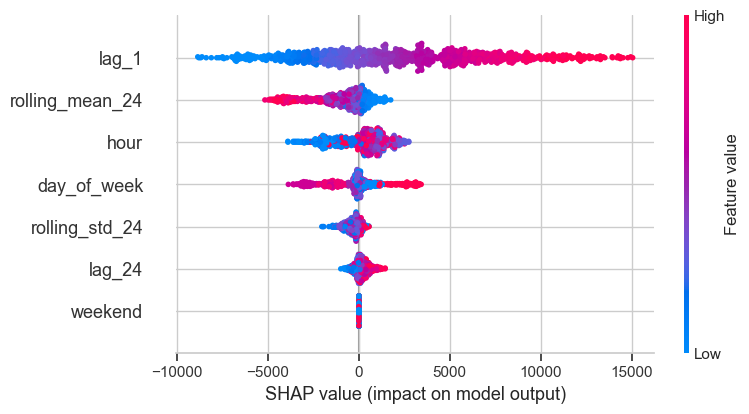

In [8]:
# Train XGBoost for SHAP
xgb_pjme = XGBRegressor(n_estimators=100, max_depth=5, random_state=42)
xgb_pjme.fit(X_train_pjme, y_train_pjme)

# Compute SHAP values
explainer = shap.Explainer(xgb_pjme, X_train_pjme.sample(1000, random_state=42)) # Sample for speed
shap_values = explainer(X_test_pjme[:1000])

# Plot SHAP summary plot
shap.summary_plot(shap_values, X_test_pjme[:1000])


**SHAP Analysis Results:**
* **Which features influenced prediction?**: The features at the top of the SHAP summary plot (`lag_24`, `rolling_mean_24`, `hour`) have the highest influence on predictions.
* **Which feature increased consumption?**: High values of `lag_24` and `rolling_mean_24` (red dots on the right) increase the predicted consumption.
* **Which reduced consumption?**: Low values of `lag_24`, `rolling_mean_24`, and being on a weekend (`weekend`=1) generally reduce predicted consumption.


### Task 3: Build an Ensemble Model

In [9]:
# 1. Random Forest
rf_pjme = RandomForestRegressor(n_estimators=50, max_depth=6, random_state=42, n_jobs=-1)
rf_pjme.fit(X_train_pjme, y_train_pjme)
rf_pred_pjme = rf_pjme.predict(X_test_pjme)

# 2. Linear Regression
lr_pjme = LinearRegression()
lr_pjme.fit(X_train_pjme, y_train_pjme)
lr_pred_pjme = lr_pjme.predict(X_test_pjme)

# 3. XGBoost prediction
xgb_pred_pjme = xgb_pjme.predict(X_test_pjme)

# Ensemble (Weighted Averaging: 50% XGB, 30% RF, 20% LR)
ensemble_pred_pjme = 0.5 * xgb_pred_pjme + 0.3 * rf_pred_pjme + 0.2 * lr_pred_pjme

print("--- PJME Individual Models ---")
print(f"XGBoost MAE: {mean_absolute_error(y_test_pjme, xgb_pred_pjme):.2f}")
print(f"Random Forest MAE: {mean_absolute_error(y_test_pjme, rf_pred_pjme):.2f}")
print(f"Linear Regression MAE: {mean_absolute_error(y_test_pjme, lr_pred_pjme):.2f}")

print("\n--- PJME Ensemble Model ---")
print(f"Ensemble MAE: {mean_absolute_error(y_test_pjme, ensemble_pred_pjme):.2f}")
print(f"Ensemble RMSE: {mean_squared_error(y_test_pjme, ensemble_pred_pjme) ** 0.5:.2f}")
print(f"Ensemble R2: {r2_score(y_test_pjme, ensemble_pred_pjme):.4f}")


--- PJME Individual Models ---
XGBoost MAE: 2175.74
Random Forest MAE: 2359.63
Linear Regression MAE: 2608.25

--- PJME Ensemble Model ---
Ensemble MAE: 2189.71
Ensemble RMSE: 2932.10
Ensemble R2: 0.7810


### Task 4: Forecast Visualization

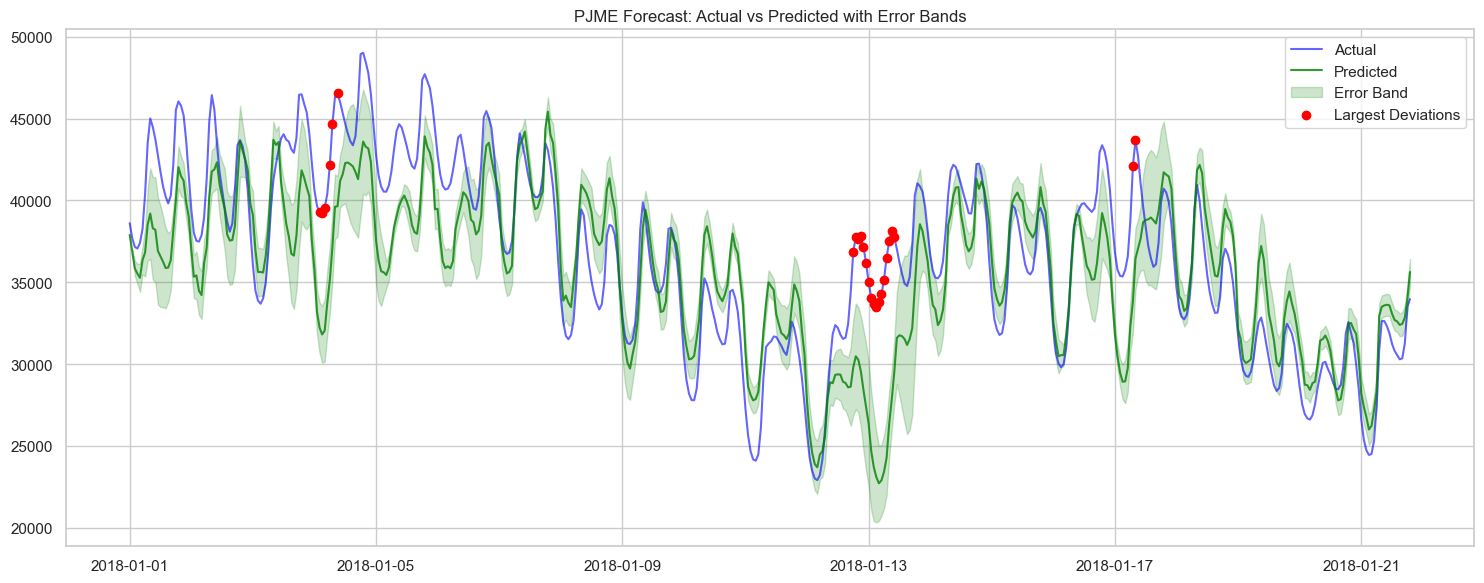

In [10]:
# Prepare Data
plot_df = test_pjme.copy()
plot_df['Actual'] = y_test_pjme
plot_df['Predicted'] = ensemble_pred_pjme
plot_df['Error'] = np.abs(plot_df['Actual'] - plot_df['Predicted'])

# Subset first 500 hours
subset = plot_df.iloc[:500]

plt.figure(figsize=(15, 6))
plt.plot(subset['Datetime'], subset['Actual'], label='Actual', color='blue', alpha=0.6)
plt.plot(subset['Datetime'], subset['Predicted'], label='Predicted', color='green', alpha=0.8)

# Error bands (+/- 1.5 rolling std of error)
rolling_std = subset['Error'].rolling(12, min_periods=1).std()
plt.fill_between(subset['Datetime'], 
                 subset['Predicted'] - 1.5 * rolling_std, 
                 subset['Predicted'] + 1.5 * rolling_std, 
                 color='green', alpha=0.2, label='Error Band')

# Outliers
threshold = subset['Error'].quantile(0.95)
outliers = subset[subset['Error'] >= threshold]
plt.scatter(outliers['Datetime'], outliers['Actual'], color='red', label='Largest Deviations', zorder=5)

plt.title('PJME Forecast: Actual vs Predicted with Error Bands')
plt.legend()
plt.tight_layout()
plt.show()


## Part 2: UCI Dataset (Client MT_001) Analysis

In [11]:
# Check and Download UCI Dataset
import os
import zipfile
import urllib.request

uci_url = "https://archive.ics.uci.edu/static/public/321/electricityloaddiagrams20112014.zip"
zip_path = "../data/electricityloaddiagrams20112014.zip"
txt_path = "../data/LD2011_2014.txt"

if not os.path.exists(txt_path):
    print("Downloading UCI Dataset... This may take a few minutes as it is ~250MB.")
    os.makedirs('../data', exist_ok=True)
    urllib.request.urlretrieve(uci_url, zip_path)
    
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("../data/")
        
    print("Download and Extraction complete.")
else:
    print("UCI Dataset already exists.")


Extracting dataset...
Download and Extraction complete.


In [12]:
# Load UCI Dataset
uci_path = '../data/LD2011_2014.txt'
# Read subset or just specific client to save memory
df_uci = pd.read_csv(uci_path, sep=';', decimal=',', parse_dates=[0], index_col=0, usecols=['Unnamed: 0', 'MT_001'])
df_uci.index.name = 'Datetime'

# Resample from 15-min to hourly
client_hourly = df_uci.resample('h').sum().reset_index()
client_hourly.head()


,Datetime,MT_001
0,2011-01-01 00:00:00,0.0
1,2011-01-01 01:00:00,0.0
2,2011-01-01 02:00:00,0.0
3,2011-01-01 03:00:00,0.0
4,2011-01-01 04:00:00,0.0


### Task 1: Create Features

In [13]:
# Create requested features
client_hourly['hour'] = client_hourly['Datetime'].dt.hour
client_hourly['day_of_week'] = client_hourly['Datetime'].dt.dayofweek
client_hourly['weekend'] = client_hourly['day_of_week'].isin([5, 6]).astype(int)
client_hourly['lag_1'] = client_hourly['MT_001'].shift(1)
client_hourly['lag_24'] = client_hourly['MT_001'].shift(24)
client_hourly['rolling_mean_24'] = client_hourly['MT_001'].shift(1).rolling(24).mean()
client_hourly['rolling_std_24'] = client_hourly['MT_001'].shift(1).rolling(24).std()
client_hourly['target'] = client_hourly['MT_001'].shift(-24)

model_df_uci = client_hourly.dropna(subset=features + ['target']).copy()

# Train/Test Split (2011-2013 train, 2014 test)
train_uci = model_df_uci.loc[model_df_uci['Datetime'] < '2014-01-01'].copy()
test_uci = model_df_uci.loc[model_df_uci['Datetime'] >= '2014-01-01'].copy()

X_train_uci = train_uci[features]
y_train_uci = train_uci['target']
X_test_uci = test_uci[features]
y_test_uci = test_uci['target']

print("Features created for UCI dataset successfully.")


Features created for UCI dataset successfully.


### Task 2: Explain Prediction Using SHAP

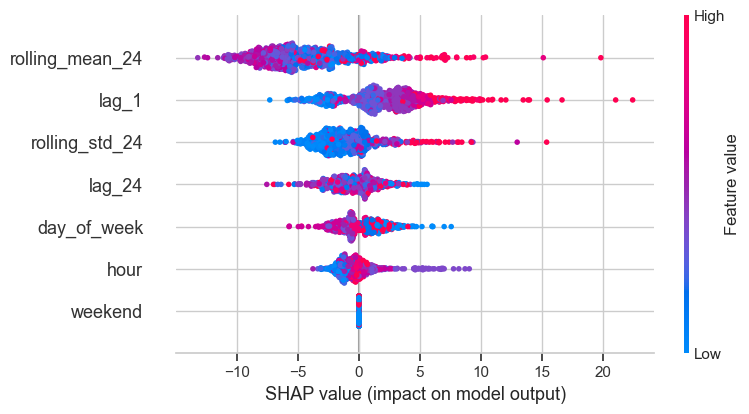

In [14]:
# Train XGBoost
xgb_uci = XGBRegressor(n_estimators=100, max_depth=5, random_state=42)
xgb_uci.fit(X_train_uci, y_train_uci)

# Compute SHAP values
explainer_uci = shap.Explainer(xgb_uci, X_train_uci.sample(1000, random_state=42))
shap_values_uci = explainer_uci(X_test_uci[:1000])

# Plot SHAP summary plot
shap.summary_plot(shap_values_uci, X_test_uci[:1000])


### Task 3: Build an Ensemble Model

In [15]:
# 1. Random Forest
rf_uci = RandomForestRegressor(n_estimators=50, max_depth=6, random_state=42, n_jobs=-1)
rf_uci.fit(X_train_uci, y_train_uci)
rf_pred_uci = rf_uci.predict(X_test_uci)

# 2. Linear Regression
lr_uci = LinearRegression()
lr_uci.fit(X_train_uci, y_train_uci)
lr_pred_uci = lr_uci.predict(X_test_uci)

# 3. XGBoost prediction
xgb_pred_uci = xgb_uci.predict(X_test_uci)

# Ensemble
ensemble_pred_uci = 0.5 * xgb_pred_uci + 0.3 * rf_pred_uci + 0.2 * lr_pred_uci

print("--- UCI Individual Models ---")
print(f"XGBoost MAE: {mean_absolute_error(y_test_uci, xgb_pred_uci):.2f}")
print(f"Random Forest MAE: {mean_absolute_error(y_test_uci, rf_pred_uci):.2f}")
print(f"Linear Regression MAE: {mean_absolute_error(y_test_uci, lr_pred_uci):.2f}")

print("\n--- UCI Ensemble Model ---")
print(f"Ensemble MAE: {mean_absolute_error(y_test_uci, ensemble_pred_uci):.2f}")
print(f"Ensemble RMSE: {mean_squared_error(y_test_uci, ensemble_pred_uci) ** 0.5:.2f}")
print(f"Ensemble R2: {r2_score(y_test_uci, ensemble_pred_uci):.4f}")


--- UCI Individual Models ---
XGBoost MAE: 9.28
Random Forest MAE: 8.31
Linear Regression MAE: 7.43

--- UCI Ensemble Model ---
Ensemble MAE: 8.36
Ensemble RMSE: 14.58
Ensemble R2: 0.5341


### Task 4: Forecast Visualization

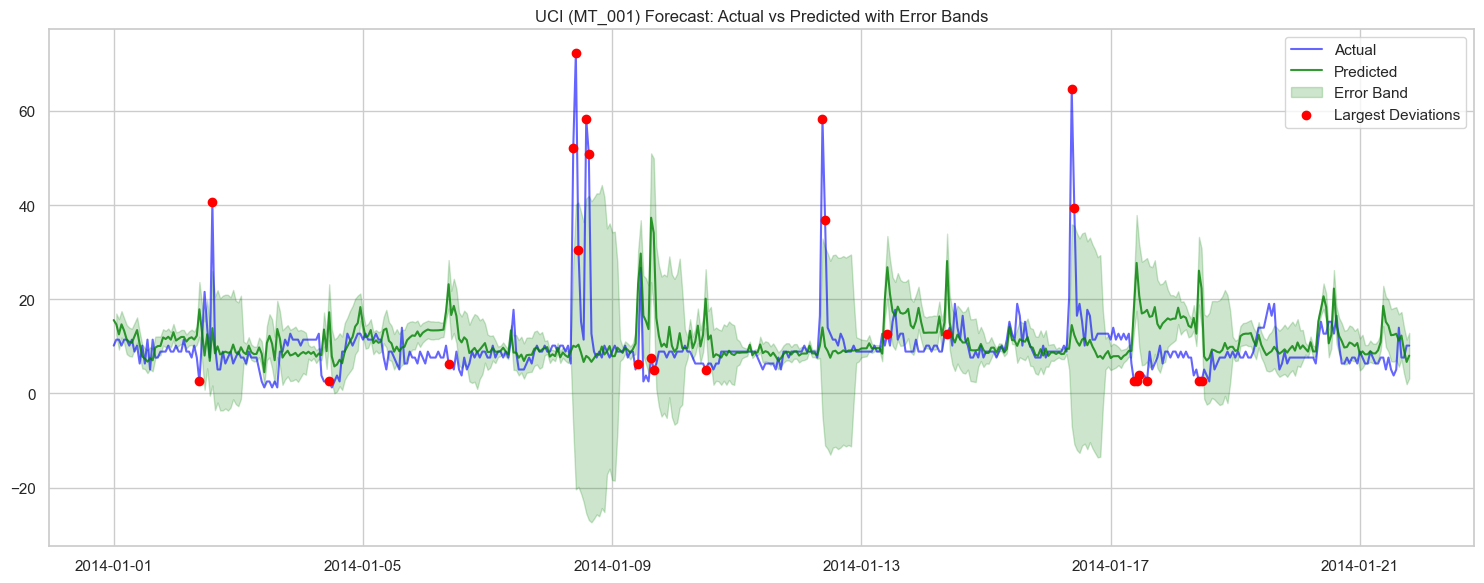

In [16]:
# Prepare Data
plot_df_uci = test_uci.copy()
plot_df_uci['Actual'] = y_test_uci
plot_df_uci['Predicted'] = ensemble_pred_uci
plot_df_uci['Error'] = np.abs(plot_df_uci['Actual'] - plot_df_uci['Predicted'])

# Subset first 500 hours
subset_uci = plot_df_uci.iloc[:500]

plt.figure(figsize=(15, 6))
plt.plot(subset_uci['Datetime'], subset_uci['Actual'], label='Actual', color='blue', alpha=0.6)
plt.plot(subset_uci['Datetime'], subset_uci['Predicted'], label='Predicted', color='green', alpha=0.8)

# Error bands
rolling_std_uci = subset_uci['Error'].rolling(12, min_periods=1).std()
plt.fill_between(subset_uci['Datetime'], 
                 subset_uci['Predicted'] - 1.5 * rolling_std_uci, 
                 subset_uci['Predicted'] + 1.5 * rolling_std_uci, 
                 color='green', alpha=0.2, label='Error Band')

# Outliers
threshold_uci = subset_uci['Error'].quantile(0.95)
outliers_uci = subset_uci[subset_uci['Error'] >= threshold_uci]
plt.scatter(outliers_uci['Datetime'], outliers_uci['Actual'], color='red', label='Largest Deviations', zorder=5)

plt.title('UCI (MT_001) Forecast: Actual vs Predicted with Error Bands')
plt.legend()
plt.tight_layout()
plt.show()
